# 🎮 Crafter x DreamerV3 100k Steps 训练与评测指南 (Google Colab)

本 Notebook 专为在 **Google Colab (免费 T4 / V100 / A100 GPU)** 上一键训练 **DreamerV3** 强化学习世界模型而设计，目标是在轻量可控的 **100k (100,000) 环境交互步数** 内快速验证世界模型的样本效率并解锁 Crafter 基础生存成就。

### 🛠️ 整体流程概览:
1. **检查 GPU 算力资源** (确认 T4/A100 与 CUDA 驱动正常)
2. **一键拉取仓库与核心依赖** (danijar/dreamerv3 + crafter + JAX 依赖 + JAX 兼容补丁)
3. **优化 JAX 显存策略** (按需申请显存，防止 OOM)
4. **启动 100k 步训练任务** (采用 Crafter 官方预设与 size12m 推荐配置)
5. **训练成果评估与 22 项成就解锁可视化**
6. **打包下载权重与评测日志**


## 1. 检查 GPU 算力环境
Colab 菜单 -> **代码执行程序 (Runtime)** -> **更改运行时类型 (Change runtime type)** -> 硬件加速器选择 **T4 GPU**。

In [1]:
import shutil
import subprocess

# 1. 检查并打印 GPU 硬件状态 (显式捕获输出以兼容 VS Code 和 Colab 网页端)
if shutil.which("nvidia-smi"):
    res = subprocess.run(["nvidia-smi"], capture_output=True, text=True, check=False)
    if res.stdout:
        print(res.stdout, flush=True)
    if res.stderr:
        print(res.stderr, flush=True)
else:
    print("未检测到 nvidia-smi 工具（当前实例未分配 GPU 硬件或处于纯 CPU 运行时）。", flush=True)

# 2. 检查 JAX 加速设备
print("\n--- JAX 计算设备检测 ---", flush=True)
try:
    import jax
    devices = jax.devices()
    print("当前 JAX 可用计算设备:", devices, flush=True)
    has_gpu = any(d.platform == "gpu" for d in devices)
except ImportError:
    has_gpu = False
    print("当前环境尚未安装 JAX，将在下一步依赖安装中自动配置。", flush=True)

if not has_gpu:
    print("\n" + "!" * 70, flush=True)
    print("【重要提示】当前未检测到 GPU 算力加速器（处于 CPU 模式）！", flush=True)
    print("若在 Google Colab 上运行，请切换为 GPU 运行时：", flush=True)
    print("👉 顶部菜单: 代码执行程序 (Runtime) -> 更改运行时类型 (Change runtime type)", flush=True)
    print("👉 硬件加速器选择: T4 GPU -> 点击 保存 (Save)", flush=True)
    print("!" * 70 + "\n", flush=True)
else:
    print("\n✅ GPU 加速器已就绪，可顺畅继续执行后续训练步骤！", flush=True)


Mon Oct 26 08:53:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. (可选) 挂载 Google Drive
> 推荐挂载 Google Drive，训练产生的日志和权重将可直接存入网盘，避免 Colab 意外掉线导致训练丢失。

In [3]:
# 如果需要挂载 Google Drive，请取消下行注释
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


## 3. 拉取 DreamerV3 官方源码与安装依赖
本步骤自动克隆官方 `danijar/dreamerv3` 仓库，安装 `crafter` 与核心依赖，并自动应用新版 JAX 关键字参数兼容补丁。

In [2]:
import os
import subprocess
import sys
from pathlib import Path

# 1. 克隆官方 DreamerV3 仓库
repo_dir = Path("/content/dreamerv3")
if not (repo_dir / "dreamerv3" / "main.py").exists():
    subprocess.run(["git", "clone", "https://github.com/danijar/dreamerv3.git", str(repo_dir)], check=True)
else:
    print("DreamerV3 仓库已就绪。")

# 2. 安装核心依赖包
pkgs = [
    "crafter",
    "elements",
    "portal",
    "ninjax",
    "optax",
    "chex",
    "einops",
    "ruamel.yaml",
    "scope",
    "matplotlib",
    "pandas",
]
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)

# 3. 自动注入新版 JAX jit 兼容补丁
main_file = repo_dir / "dreamerv3" / "main.py"
if main_file.exists():
    content = main_file.read_text(encoding="utf-8")
    patch_marker = "# === JAX COMPATIBILITY MONKEY PATCH ==="
    if patch_marker not in content:
        patch_lines = [
            patch_marker,
            "import jax",
            "_orig_jit = jax.jit",
            "def _compat_jit(fun=None, *args, **kwargs):",
            "    if not args:",
            "        return _orig_jit(fun, **kwargs)",
            "    names = ['in_shardings', 'out_shardings', 'static_argnums', 'static_argnames', 'donate_argnums']",
            "    for val, name in zip(args, names):",
            "        if val is not None and name not in kwargs and name != 'static_argnames':",
            "            kwargs[name] = val",
            "    return _orig_jit(fun, **kwargs)",
            "jax.jit = _compat_jit",
            "",
        ]
        patch_code = "\n".join(patch_lines)
        main_file.write_text(patch_code + "\n" + content, encoding="utf-8")
        print("已成功注入 JAX jit 兼容补丁！")

print("\n所有核心依赖与环境补丁安装完成！")


已成功注入 JAX jit 兼容补丁！

所有核心依赖与环境补丁安装完成！


## 4. JAX 显存策略与环境变量配置
JAX 默认会直接预分配 90% 显存。在单 GPU 且需多任务协作的 Colab 上，关闭预分配以按需申请显存，提升稳定性。

In [4]:
import os
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "0.85"
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"
print("JAX 显存优化参数已注入系统环境。")


JAX 显存优化参数已注入系统环境。


## 5. 启动 DreamerV3 100k 训练

### 核心参数详解:
- `--configs crafter size12m`: 启用官方 Crafter 场景参数（64x64 图像、离散动作空间），并配置约为 12M 参数的平衡模型（在 T4 上兼具极快训练速度与丰富表征能力）。
- `--task crafter_reward`: 使用带成就奖励的标准生存任务。
- `--run.steps 100000`: 严格限制训练 100,000 环境交互步。
- `--run.train_ratio 512`: 保持官方推荐的高样本复用比率。
- `--run.log_every 30`: 每 30 秒更新一次指标日志。
- `--run.save_every 300`: 每 5 分钟自动保存一次 checkpoint。

In [5]:
import os
import subprocess
import sys

output_dir = "/content/output/crafter_dreamerv3_100k"
os.makedirs(output_dir, exist_ok=True)
repo_dir = "/content/dreamerv3"

cmd = [
    sys.executable,
    f"{repo_dir}/dreamerv3/main.py",
    "--configs", "crafter", "size12m",
    "--task", "crafter_reward",
    "--logdir", output_dir,
    "--run.steps", "100000",
    "--run.train_ratio", "512",
    "--run.log_every", "30",
    "--run.save_every", "300",
    "--jax.prealloc", "False",
]

env = os.environ.copy()
env["PYTHONPATH"] = repo_dir + os.pathsep + env.get("PYTHONPATH", "")

proc = subprocess.Popen(cmd, cwd=repo_dir, env=env, text=True)
proc.wait()


: 

: 

In [1]:
import shutil
from pathlib import Path
from google.colab import drive

# 1. 挂载 Google 云端硬盘
print("正在请求挂载 Google Drive...")
drive.mount('/content/drive')

# 2. 将训练成果完整同步到云盘
src_dir = '/content/output/crafter_dreamerv3_100k'
dst_dir = '/content/drive/MyDrive/crafter_dreamerv3_100k'

print("正在将模型权重与日志复制到你的云盘，请稍候...")
shutil.copytree(src_dir, dst_dir, dirs_exist_ok=True)

print("\n" + "=" * 50)
print(f"🎉 成功！所有 249+ 局模型权重与数据已永久存入你的 Google Drive！")
print(f"📁 云盘路径: 我的云端硬盘/crafter_dreamerv3_100k")
print("=" * 50)


正在请求挂载 Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
正在将模型权重与日志复制到你的云盘，请稍候...

🎉 成功！所有 249+ 局模型权重与数据已永久存入你的 Google Drive！
📁 云盘路径: 我的云端硬盘/crafter_dreamerv3_100k


## 6. 训练结果可视化与 Crafter 成就解锁分析
解析 `metrics.jsonl`，绘制训练得分曲线与 22 项生存成就达成率。

成功载入 782 条指标记录！


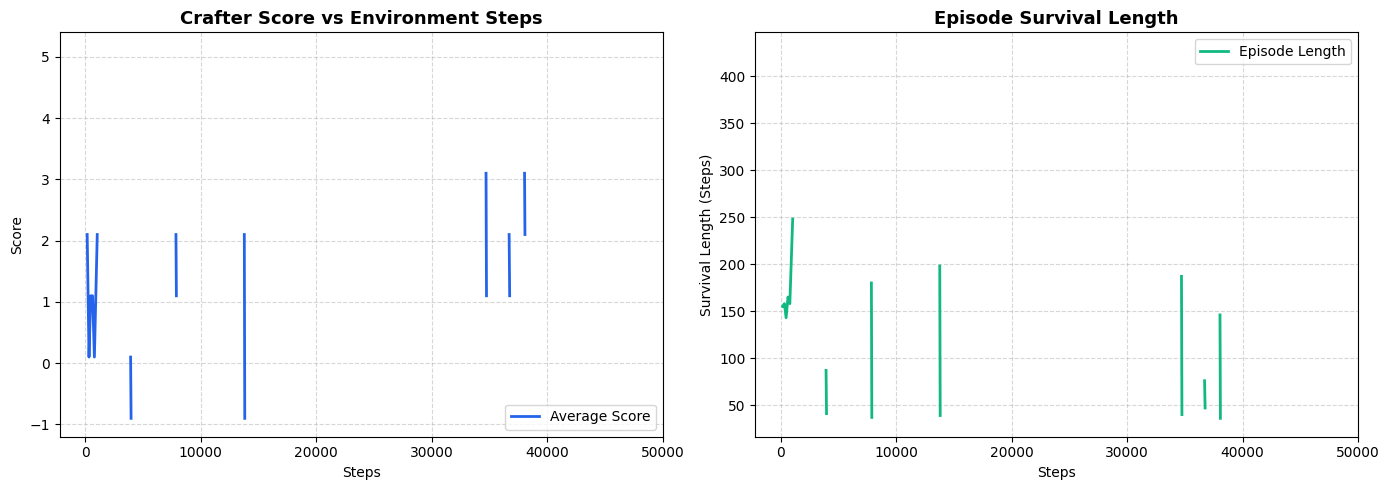

In [5]:
import json
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

metrics_file = Path("/content/output/crafter_dreamerv3_100k/metrics.jsonl")
if not metrics_file.exists():
    files = list(Path("/content/output/crafter_dreamerv3_100k").glob("**/metrics.jsonl"))
    if files:
        metrics_file = files[0]

if metrics_file.exists():
    records = []
    with open(metrics_file, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                try:
                    records.append(json.loads(line))
                except Exception:
                    pass

    df = pd.DataFrame(records)
    print(f"成功载入 {len(df)} 条指标记录！")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    score_col = "episode/score" if "episode/score" in df.columns else "score"
    len_col = "episode/length" if "episode/length" in df.columns else "length"

    if score_col in df.columns and "step" in df.columns:
        axes[0].plot(df["step"], df[score_col], color="#2563EB", linewidth=2, label="Average Score")
        axes[0].set_title("Crafter Score vs Environment Steps", fontsize=13, fontweight="bold")
        axes[0].set_xlabel("Steps")
        axes[0].set_ylabel("Score")
        axes[0].grid(True, linestyle="--", alpha=0.5)
        axes[0].legend()

    if len_col in df.columns and "step" in df.columns:
        axes[1].plot(df["step"], df[len_col], color="#10B981", linewidth=2, label="Episode Length")
        axes[1].set_title("Episode Survival Length", fontsize=13, fontweight="bold")
        axes[1].set_xlabel("Steps")
        axes[1].set_ylabel("Survival Length (Steps)")
        axes[1].grid(True, linestyle="--", alpha=0.5)
        axes[1].legend()

    plt.tight_layout()
    plt.show()

    last_row = df.iloc[-1]
    achievements = {}
    for col in df.columns:
        if "achievement" in col.lower():
            ach_name = col.split("/")[-1].replace("achievement_", "")
            achievements[ach_name] = float(last_row[col])
    if achievements:
        ach_series = pd.Series(achievements).sort_values(ascending=True)
        plt.figure(figsize=(10, 8))
        colors = ["#10B981" if v > 0.05 else "#9CA3AF" for v in ach_series.values]
        bars = plt.barh(ach_series.index, ach_series.values * 100, color=colors)
        plt.title("Crafter Achievement Unlock Rate at 100k Steps (%)", fontsize=14, fontweight="bold")
        plt.xlabel("Unlock Probability (%)")
        plt.grid(axis="x", linestyle="--", alpha=0.6)
        for bar in bars:
            w = bar.get_width()
            if w > 1:
                plt.text(w + 1, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va="center", fontsize=9)
        plt.tight_layout()
        plt.show()
else:
    print("未找到 metrics.jsonl 文件，请先执行训练。")


## 7. 打包模型与下载到本地


In [6]:
import shutil
from google.colab import files

zip_filename = "/content/crafter_dreamerv3_100k.zip"
shutil.make_archive("/content/crafter_dreamerv3_100k", "zip", "/content/output/crafter_dreamerv3_100k")
print(f"压缩打包完成: {zip_filename}")

files.download(zip_filename)


压缩打包完成: /content/crafter_dreamerv3_100k.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>